# Supplementary Fig. S6: Decoding reinforcement learning-based Q-values from neural population activity

[AI generated summary] Time-resolved linear decoders (ridge regression, 10-fold cross-validation) trained on the population activity of each session to decode the Q-values Q1, Q2 and Q3 of the inferential RL model (a) and of the standard RL model (b), computed with the models fitted to each monkey's choices. The curves show the percentage of sessions with significant decoding (permutation test, p < 0.05 in at least 2 consecutive 100-ms bins, positive R²) in MCC, dLPFC and vLPFC, for each monkey. Same plotting function as Fig. 3f (`fig3f_population_decoding.ipynb`).

**How to run:** set `DATA_PATH` in `popy/config.py` (uses `behavior/recordings_summary.csv`), then run all cells. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/population_decoding/alternative_model_values` (see the README). To recompute them, run in this folder: `python run_decoding.py alternative_model_values` (about 1.5 days on a server).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
##% imports
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

from popy.plotting.plotting_tools import plot_keypoints
from popy.config import COLORS

from helpers_decoding import load_decoding_res_new, mask_N_consecutives, add_subareas

# set fontsize to 8
plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def plot_simple_decoding_signif_only(
    res,
    t_window=None,
    mark_event=None,
    n_extra_trials=(0, 1),
    ylim=None,
    title=None,
    ax=None,
):
    """
    Plot only the first panel from plot_simple_decoding:
    percent significant sessions over time for MCC, dLPFC, and vLPFC.
    """
    from scipy.ndimage import uniform_filter

    axis_original = ax

    if ax is None:
        plt.rcParams.update({'font.size': 8})
        fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.0))

    for subregion in ['MCC', 'dLPFC', 'vLPFC']:
        res_temp = (
            res.sel(area='MCC')
            if subregion == 'MCC'
            else res.sel(area='LPFC', session=res.lpfc_subregion == subregion)
        )

        signif_data_in_time = res_temp.if_significant.mean(dim='session')
        signif_data_in_time_smooth = uniform_filter(
            signif_data_in_time, size=5, mode='constant', cval=0.0
        )
        signif_data_in_time_smooth = signif_data_in_time_smooth * 100

        ax.plot(
            res_temp.time,
            signif_data_in_time_smooth,
            color=COLORS[subregion],
            label=subregion,
            lw=1.2,
        )

    plot_keypoints(
        ax,
        n_extra_trials=n_extra_trials,
        fontsize=8,
        rotation=0,
        mark_event=mark_event,
        xlabels='short',
    )
    ax.grid(axis='x', alpha=0.5, linestyle='--')

    # set y ticks 0 .25, .5, .75, 100
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_yticklabels(['0', '25', '50', '75', '100'])

    if title is not None:
        ax.set_title(title, fontsize=8)
    if ylim is not None:
        ax.set_ylim(ylim)

    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Percent signif.\nsessions (%)')

    if t_window is not None:
        ax.set_xlim(t_window)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    #plt.tight_layout()

    if axis_original is None:
        return fig, ax
    return ax

In [4]:
def mask_negative_scores(res, plot_res=False):
    """
    Mask negative scores in the results.
    """
    signifs = res['if_significant'].data
    scores = res['scores'].data

    scores_negative = scores <= 0  # mask negative scores
    signifs_new = np.logical_and(signifs, ~scores_negative)  # keep only significant scores that are not negative

    print(f"Masked negative scores: {np.sum(scores_negative)} out of {scores.size} total scores.")

    # plot the number of masked values, i.e. signif and negative
    if plot_res:
        fig, ax = plt.subplots(figsize=(6, 3))
        ax.plot(res.time, np.convolve(signifs.sum(0)[:, 1], np.ones(1)/1, mode='same'), color='black')
        ax.plot(res.time, np.convolve(np.logical_and(signifs, scores_negative).sum(0)[:, 1], np.ones(1)/1, mode='same'), color='red')
        ax.plot(res.time, np.convolve(signifs_new.sum(0)[:, 1], np.ones(1)/1, mode='same'), color='green')
        plot_keypoints(ax, n_extra_trials=(-1, 0), fontsize=8, rotation=0, mark_event=None, xlabels='short')
        ax.grid(axis='x', alpha=.5, linestyle='--')
        ax.legend(['All significant', 'Significant & negative', 'Significant & non-negative'])
        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Number of sessions')
        ax.set_title('Masking negative scores\nRed: signif. & negative, Green: signif. & non-negative')
    
        plt.show()
        plt.close()

    res['if_significant'].data = signifs_new  # update the significants in the results
    return res

---
# Supplementary Fig. S6a, b: Decoding the Q-values of the inferential (a) and standard (b) RL models

Masked negative scores: 26159 out of 34200 total scores.


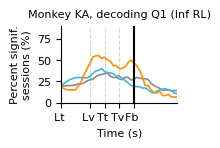

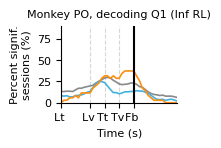

Masked negative scores: 19493 out of 34200 total scores.


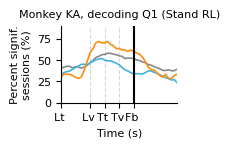

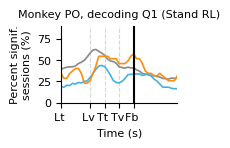

Masked negative scores: 26328 out of 34200 total scores.


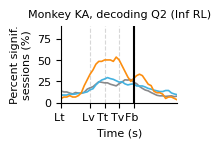

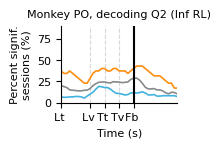

Masked negative scores: 20188 out of 34200 total scores.


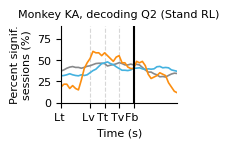

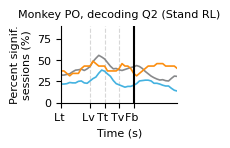

Masked negative scores: 26473 out of 34200 total scores.


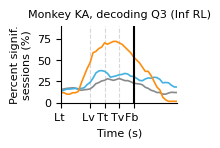

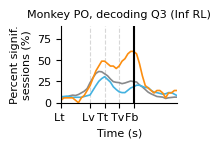

Masked negative scores: 19383 out of 34200 total scores.


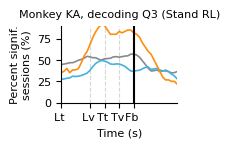

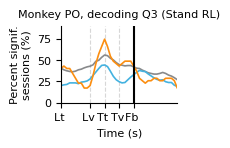

In [5]:
# for each monkey and each target variable (fb, value, target), we plot the 3 areas

plim = .05
n_extra_trials = (0, 1)
N_consecutives = 2

paper_format=True

def target_tits(target):
    """
    Converts from computer naming to printable names as
    
    Q_1_inf -> Q1 (Inferential RL)
    Q_1_stand -> Q1 (Standard RL)
    """
    if target.startswith('Q'):
        return f'Q{target.split("_")[1]} ({target.split("_")[2].capitalize()} RL)'
    return target

configs = {
    'Q_1_inf': {
        'target': 'Q_1_inf',
        'folder': 'alternative_model_values',
        't_window': [1, 5],
    },
    'Q_1_stand': {
        'target': 'Q_1_stand',
        'folder': 'alternative_model_values',
        't_window': [1, 5],
    },
    'Q_2_inf': {
        'target': 'Q_2_inf',
        'folder': 'alternative_model_values',
        't_window': [1, 5],
    },
    'Q_2_stand': {
        'target': 'Q_2_stand',
        'folder': 'alternative_model_values',
        't_window': [1, 5],
    },
    'Q_3_inf': {
        'target': 'Q_3_inf',
        'folder': 'alternative_model_values',
        't_window': [1, 5],
    },
    'Q_3_stand': {
        'target': 'Q_3_stand',
        'folder': 'alternative_model_values',
        't_window': [1, 5],
    },
}

for config_name, config in configs.items():
    target = config['target']
    folder = config['folder']
    t_window = config['t_window']

    # load results

    res = load_decoding_res_new(folder=folder)
    res = add_subareas(res)  # add subareas to the results 
    res = res.sel(target=target)  # select target of interest, e.g. feedback or value

    # if 'group' in dims and its nan, remove it. if not nan, raise error
    if 'group_target' in res.dims:
        if res.group_target == 'None':
            res = res.mean('group_target')
        else:
            raise ValueError("group_target was used so the plotting method cant handle this.")
        
    # mask significants
    res_target_signifs = mask_N_consecutives(res.pvals <= plim, N=N_consecutives)  # mask N consecutive non-significant bins
    res['if_significant'] = res_target_signifs  # add as new dataarray to the results
    res = mask_negative_scores(res, plot_res=False)  # mask negative scores, only for ka monkey

    for monkey in np.unique(res.monkey.values):
        res_temp = res.sel(session=res.monkey == monkey)
        title = f'Monkey {monkey.upper()}, decoding {target_tits(target)}'
        fig, axs = plot_simple_decoding_signif_only(res_temp, t_window=t_window, mark_event='Fb', n_extra_trials=n_extra_trials, title=title, ylim=(0, 90))

        # save the figure
        floc = os.path.join(FIGS_PATH, f'figS6_{monkey}_{target}_decoding.svg')
        plt.savefig(floc, bbox_inches='tight', dpi=300, transparent=True)
        plt.show()
        plt.close()

In [6]:
# Export source data (Supplementary Figure 6a, b)
from popy.source_data import export_source_data
import pandas as pd
from scipy.ndimage import uniform_filter

# curves as computed in plot_simple_decoding_signif_only (same results, masking and smoothing as above), within the plotted window
sd_time_col = 'Time in the normalized trial (s)'
sd_models = {'Supplementary Figure 6a': 'inf', 'Supplementary Figure 6b': 'stand'}
sd_check = {}
for sd_panel, sd_model in sd_models.items():
    sd_tables, sd_n_sessions = {}, []
    for config_name, config in configs.items():
        if not config_name.endswith(f'_{sd_model}'):
            continue
        sd_res = load_decoding_res_new(folder=config['folder'])
        sd_res = add_subareas(sd_res)
        sd_res = sd_res.sel(target=config['target'])
        sd_res['if_significant'] = mask_N_consecutives(sd_res.pvals <= plim, N=N_consecutives)
        sd_res = mask_negative_scores(sd_res, plot_res=False)

        for sd_monkey in np.unique(sd_res.monkey.values):
            sd_res_monkey = sd_res.sel(session=sd_res.monkey == sd_monkey)
            sd_df = pd.DataFrame({sd_time_col: np.round(sd_res_monkey.time.values, 3)})
            for subregion in ['MCC', 'dLPFC', 'vLPFC']:
                sd_res_area = (sd_res_monkey.sel(area='MCC') if subregion == 'MCC'
                               else sd_res_monkey.sel(area='LPFC', session=sd_res_monkey.lpfc_subregion == subregion))
                sd_curve = uniform_filter(sd_res_area.if_significant.mean(dim='session'), size=5, mode='constant', cval=0.0) * 100
                sd_df[f'{subregion}, significant sessions (%)'] = np.round(sd_curve, 10)  # (rounding removes float noise)
                sd_n_sessions.append({'Decoded variable': target_tits(config['target']), 'Monkey': sd_monkey.upper(),
                                      'Region': subregion, 'Number of sessions (n)': sd_res_area.sizes['session'],
                                      'of which without decoding results (counted as non-significant)':
                                          int(sd_res_area.pvals.isnull().all('time').sum())})
            sd_window = config['t_window']
            sd_visible = (sd_df[sd_time_col] >= sd_window[0] - 1e-6) & (sd_df[sd_time_col] <= sd_window[1] + 1e-6)
            sd_tables[f'{target_tits(config["target"])} decoding, monkey {sd_monkey.upper()}'] = sd_df[sd_visible].reset_index(drop=True)
            sd_check[(config_name, sd_monkey)] = (sd_res_monkey, sd_window, sd_tables[f'{target_tits(config["target"])} decoding, monkey {sd_monkey.upper()}'])
    sd_tables['Number of sessions'] = pd.DataFrame(sd_n_sessions)

    export_source_data(
        sd_panel, sd_tables,
        f'Percentage of sessions with significant decoding of the Q-values Q1, Q2 and Q3 of the '
        f'{"inferential" if sd_model == "inf" else "standard"} RL model (ridge regression, R2 > 0 and permutation test '
        f'p < 0.05 in at least 2 consecutive 100-ms bins) in MCC, dLPFC and vLPFC, for each monkey, as a function of time in '
        f'the normalized trial (s; time markers Lt = 1 s, Tt = 2.5 s, Fb = 3.5 s), within the plotted window. Curves are '
        f'smoothed with a 5-bin moving average; the exported values are the smoothed values drawn. n = number of sessions '
        f'per curve (last table).'
    )

Masked negative scores: 26159 out of 34200 total scores.
Masked negative scores: 26328 out of 34200 total scores.
Masked negative scores: 26473 out of 34200 total scores.
Supplementary Figure 6a: source data saved (41 rows, 41 rows, 41 rows, 41 rows, 41 rows, 41 rows, 18 rows)
Masked negative scores: 19493 out of 34200 total scores.
Masked negative scores: 20188 out of 34200 total scores.
Masked negative scores: 19383 out of 34200 total scores.
Supplementary Figure 6b: source data saved (41 rows, 41 rows, 41 rows, 41 rows, 41 rows, 41 rows, 18 rows)
